# **Development and Evaluation of Explainable Machine Learning Models for Type 2 Diabetes Risk Screening**



### **Part 0: Tools**

In [1]:
## ส่วนที่ 0 — เตรียมเครื่องมือ
# จัดการคำเตือนและตั้งค่า random seed
import warnings
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# แสดงผลตารางและตั้งค่ากราฟ
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 110

# แบ่งข้อมูลและสร้าง pipeline ป้องกัน data leakage
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# โมเดล
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

# การประเมินผล
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

# การตีความโมเดล
from sklearn.inspection import permutation_importance

print("พร้อมใช้งาน")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

พร้อมใช้งาน
NumPy version: 2.1.3
Pandas version: 2.2.3


### **Part 1: Medical question:**

**คำถาม:** จากข้อมูลสุขภาพและพฤติกรรมที่ไม่ต้องตรวจเลือด เราสามารถคัดกรองบุคคลที่มีความเสี่ยง T2DM สูงได้หรือไม่

**ใช้ตอนไหน:** โมเดลใช้เป็นเครื่องมือคัดกรองเบื้องต้น เช่น ใช้ร่วมกับแบบสอบถามสุขภาพหรือกิจกรรมตรวจสุขภาพในชุมชน หากโมเดลประเมินว่าบุคคลมีความเสี่ยงสูง ควรแนะนำให้เข้ารับการตรวจยืนยันด้วยการตรวจเลือดตามแนวทางมาตรฐาน

**ทำนายอะไรทางเทคนิค:** `t2dm = 1`  หมายถึง มี T2DM
`t2dm = 0` หมายถึง ไม่มี T2DM

**ตัวชี้วัดที่ให้น้ำหนัก:** จะมีการให้ความสำคัญกับค่า Recall เป็นหลัก เพราะ false negative คือกรณีที่บุคคลมี T2DM จริง แต่โมเดลประเมินว่าไม่มีความเสี่ยง ซึ่งอาจทำให้ไม่ได้รับการตรวจยืนยันหรือคำแนะนำที่เหมาะสม
และค่า Precision, ROC-AUC, PR-AUC และ confusion matrix เพื่อพิจารณาสมดุลระหว่างการตรวจพบผู้เสี่ยงจริงกับจำนวนผู้ที่ถูกแนะนำให้ตรวจเพิ่มเติมโดยไม่จำเป็น

### **Part 2: Preparing Data**
1. ใช้ข้อมูลจำลอง 2,000 คน ไม่ใช่ข้อมูลผู้ป่วยจริง  
2. มี 12 features: อายุ เพศ BMI รอบเอว ความดันตัวบน ความดันสูง ประวัติครอบครัว การออกกำลังกาย คะแนนอาหาร ชั่วโมงนอน สูบบุหรี่ และ HDL  
3. สร้างตัวแปรให้สัมพันธ์กัน เช่น BMI สูงทำให้รอบเอวและความดันสูงขึ้น  
4. กำหนดปัจจัยเสี่ยง T2DM เองด้วย TRUE_COEF  
5. BMI, รอบเอว, อายุ, ความดันสูง และประวัติครอบครัว เพิ่มความเสี่ยง  
6. การออกกำลังกาย คะแนนอาหาร HDL และการนอนมากขึ้น ลดความเสี่ยง  
7. ใช้สมการ logistic regression สร้างความน่าจะเป็นของ T2DM  
8. สุ่ม target t2dm จากความน่าจะเป็น เพื่อให้มี noise และโมเดลทำนายไม่ถูก 100%  
9. ปรับ intercept ให้ prevalence ของ T2DM ประมาณ 18%  
10. ใส่ missing values แบบสุ่มประมาณ 4% ในแต่ละ feature  
11. เก็บ TRUE_COEF ไว้เทียบกับสิ่งที่โมเดลเรียนรู้ในส่วน explainability  
12. ผลทั้งหมดใช้เป็น synthetic proof-of-concept เท่านั้น

In [2]:
import numpy as np
import pandas as pd

SEED = 42
rng = np.random.default_rng(SEED)
n = 2000

# 1) สร้างข้อมูลพื้นฐานและความสัมพันธ์ระหว่างตัวแปร
age = np.clip(rng.normal(52, 13, n), 18, 85)
sex = rng.binomial(1, 0.48, n)  # 1 = male, 0 = female

family_history = rng.binomial(1, 0.28, n)

diet_score = np.clip(rng.normal(5.5, 1.8, n), 0, 10)  # สูง = พฤติกรรมการกินดีกว่า
physical_activity = np.clip(
    rng.normal(165 - 1.3 * (age - 52), 65, n), 0, 420
)  # นาที/สัปดาห์

smoking = rng.binomial(
    1,
    1 / (1 + np.exp(-(-1.2 + 0.45 * sex))),
    n
)

bmi = np.clip(
    25
    + 0.05 * (age - 52)
    - 0.008 * (physical_activity - 165)
    - 0.20 * (diet_score - 5.5)
    + 0.9 * family_history
    + rng.normal(0, 3.8, n),
    16, 45
)

waist_circumference = np.clip(
    84
    + 2.2 * (bmi - 25)
    + 3.5 * sex
    + rng.normal(0, 6, n),
    55, 140
)

systolic_bp = np.clip(
    116
    + 0.48 * (age - 52)
    + 0.70 * (bmi - 25)
    + rng.normal(0, 11, n),
    85, 220
)

hypertension_prob = 1 / (1 + np.exp(-(
    -5.6 + 0.052 * age + 0.085 * bmi + 0.015 * systolic_bp
)))
hypertension = rng.binomial(1, hypertension_prob, n)

sleep_hours = np.clip(
    rng.normal(7.0 - 0.20 * smoking - 0.10 * (bmi - 25) / 3, 1.0, n),
    3.5, 11
)

hdl_cholesterol = np.clip(
    54
    - 0.70 * (bmi - 25)
    - 3.0 * smoking
    - 2.5 * sex
    + 0.25 * (physical_activity - 165) / 10
    + rng.normal(0, 9, n),
    20, 100
)

# 2) รวม 12 features
X_complete = pd.DataFrame({
    "age": age,
    "sex": sex,
    "bmi": bmi,
    "waist_circumference": waist_circumference,
    "systolic_bp": systolic_bp,
    "hypertension": hypertension,
    "family_history": family_history,
    "physical_activity": physical_activity,
    "diet_score": diet_score,
    "sleep_hours": sleep_hours,
    "smoking": smoking,
    "hdl_cholesterol": hdl_cholesterol,
})

# 3) Data-generating mechanism ของ T2DM
# แปลงทุก feature เป็น z-score เพื่อให้ coefficient เปรียบเทียบกันได้
Z = (X_complete - X_complete.mean()) / X_complete.std(ddof=0)

TRUE_COEF = {
    "age": 0.45,
    "sex": 0.05,
    "bmi": 0.75,
    "waist_circumference": 0.50,
    "systolic_bp": 0.30,
    "hypertension": 0.55,
    "family_history": 0.65,
    "physical_activity": -0.40,
    "diet_score": -0.28,
    "sleep_hours": -0.15,
    "smoking": 0.18,
    "hdl_cholesterol": -0.25,
}

linear_risk = sum(TRUE_COEF[col] * Z[col] for col in TRUE_COEF)

# ปรับ intercept ให้ expected prevalence ใกล้ 18%
target_prevalence = 0.18
low, high = -10, 10

for _ in range(100):
    b0 = (low + high) / 2
    probability = 1 / (1 + np.exp(-(b0 + linear_risk)))

    if probability.mean() > target_prevalence:
        high = b0
    else:
        low = b0

probability = 1 / (1 + np.exp(-(b0 + linear_risk)))
t2dm = rng.binomial(1, probability, n)

# 4) ใส่ missingness ประมาณ 4% ของแต่ละ feature
df = X_complete.copy()

for col in X_complete.columns:
    missing_mask = rng.random(n) < 0.04
    df.loc[missing_mask, col] = np.nan

# เพิ่ม ID และ target
df.insert(0, "participant_id", range(1, n + 1))
df["t2dm"] = t2dm

# บันทึกไฟล์
df.to_csv("mock_t2dm_2000.csv", index=False)

print(f"Dataset shape: {df.shape}")
print(f"T2DM prevalence: {df['t2dm'].mean():.1%}")
print("\nMissingness per feature:")
print((df.isna().mean() * 100).round(1))
display(df.head())

print("\nTRUE_COEF:")
print(pd.Series(TRUE_COEF).sort_values(key=np.abs, ascending=False))

Dataset shape: (2000, 14)
T2DM prevalence: 17.1%

Missingness per feature:
participant_id         0.0
age                    3.6
sex                    4.5
bmi                    4.1
waist_circumference    4.2
systolic_bp            4.0
hypertension           4.0
family_history         3.6
physical_activity      4.1
diet_score             4.3
sleep_hours            3.1
smoking                4.0
hdl_cholesterol        4.0
t2dm                   0.0
dtype: float64


,participant_id,age,sex,bmi,waist_circumference,systolic_bp,hypertension,family_history,physical_activity,diet_score,sleep_hours,smoking,hdl_cholesterol,t2dm
0,1,55.961322,0.0,25.622670,83.722336,120.369064,1.0,0.0,230.193108,5.208158,4.418502,0.0,58.612129,0
1,2,38.480207,0.0,21.798768,79.343357,115.879619,0.0,0.0,148.688902,5.743767,9.036933,0.0,63.248628,0
2,3,61.755866,1.0,25.389547,88.969570,123.958354,1.0,0.0,104.027525,8.592580,5.448570,1.0,56.160731,0
3,4,64.227341,0.0,29.186077,96.193887,132.101192,1.0,0.0,197.293281,5.068515,7.355576,0.0,59.754638,0
4,5,26.636543,0.0,23.595634,72.905782,101.477045,0.0,0.0,235.340469,5.594702,7.474228,0.0,48.478636,0



TRUE_COEF:
bmi                    0.75
family_history         0.65
hypertension           0.55
waist_circumference    0.50
age                    0.45
physical_activity     -0.40
systolic_bp            0.30
diet_score            -0.28
hdl_cholesterol       -0.25
smoking                0.18
sleep_hours           -0.15
sex                    0.05
dtype: float64


| กลุ่ม | ตัวแปร |
|---|---|
| Demographic | `age`, `sex` |
| Anthropometric | `bmi`, `waist_circumference` |
| Vital signs/history | `systolic_bp`, `hypertension`, `family_history` |
| Lifestyle | `physical_activity`, `diet_score`, `sleep_hours`, `smoking` |
| Metabolic proxy | `hdl_cholesterol` |

### **Part3 : Exploratory Data Analysis**

สำรวจข้อมูลก่อนนำไปแบ่ง train, validation และ test เพื่อให้เห็นลักษณะของข้อมูลดิบ

1. ขนาดข้อมูล ชนิดข้อมูล และตัวอย่างข้อมูล

2. สัดส่วนผู้มีและไม่มี T2DM

3. จำนวน missing values ของแต่ละ feature

4. ค่าสถิติเชิงพรรณนาและการกระจายของตัวแปรสำคัญ

5. ความสัมพันธ์ระหว่าง features

In [3]:
# 3.1 ภาพรวมของข้อมูล
print(f"จำนวนข้อมูล: {df.shape[0]} คน")
print(f"จำนวนคอลัมน์ทั้งหมด: {df.shape[1]} คอลัมน์")

display(df.head())

print("\nชนิดข้อมูล:")
display(df.dtypes)

จำนวนข้อมูล: 2000 คน
จำนวนคอลัมน์ทั้งหมด: 14 คอลัมน์


,participant_id,age,sex,bmi,waist_circumference,systolic_bp,hypertension,family_history,physical_activity,diet_score,sleep_hours,smoking,hdl_cholesterol,t2dm
0,1,55.961322,0.0,25.622670,83.722336,120.369064,1.0,0.0,230.193108,5.208158,4.418502,0.0,58.612129,0
1,2,38.480207,0.0,21.798768,79.343357,115.879619,0.0,0.0,148.688902,5.743767,9.036933,0.0,63.248628,0
2,3,61.755866,1.0,25.389547,88.969570,123.958354,1.0,0.0,104.027525,8.592580,5.448570,1.0,56.160731,0
3,4,64.227341,0.0,29.186077,96.193887,132.101192,1.0,0.0,197.293281,5.068515,7.355576,0.0,59.754638,0
4,5,26.636543,0.0,23.595634,72.905782,101.477045,0.0,0.0,235.340469,5.594702,7.474228,0.0,48.478636,0



ชนิดข้อมูล:


,0
participant_id,int64
age,float64
sex,float64
bmi,float64
waist_circumference,float64
systolic_bp,float64
hypertension,float64
family_history,float64
physical_activity,float64
diet_score,float64


In [4]:
# 3.2 สัดส่วนของ target
class_counts = df["t2dm"].value_counts().sort_index()
class_percent = df["t2dm"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "count": class_counts,
    "percent": class_percent.round(2)
}, index=["No T2DM (0)", "T2DM (1)"])

display(class_summary)

,count,percent
No T2DM (0),NaN,NaN
T2DM (1),NaN,NaN


In [5]:
# 3.3 Missing values
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing_summary[missing_summary["missing_count"] > 0])

,missing_count,missing_percent
sex,90,4.50
diet_score,86,4.30
waist_circumference,85,4.25
bmi,82,4.10
physical_activity,82,4.10
systolic_bp,81,4.05
hdl_cholesterol,81,4.05
smoking,81,4.05
hypertension,79,3.95
family_history,72,3.60


In [6]:
# 3.4 Descriptive statistics
feature_cols = [col for col in df.columns if col not in ["participant_id", "t2dm"]]

display(
    df[feature_cols]
    .describe()
    .T[["mean", "std", "min", "50%", "max"]]
    .round(2)
)

,mean,std,min,50%,max
age,51.31,12.96,18.00,51.77,85.00
sex,0.47,0.50,0.00,0.00,1.00
bmi,25.21,3.87,16.00,25.04,38.56
waist_circumference,86.09,10.46,55.00,86.08,121.14
systolic_bp,116.47,12.96,85.00,116.75,168.97
hypertension,0.69,0.46,0.00,1.00,1.00
family_history,0.27,0.44,0.00,0.00,1.00
physical_activity,165.23,68.44,0.00,165.83,398.78
diet_score,5.50,1.79,0.00,5.41,10.00
sleep_hours,6.95,1.03,3.80,6.94,10.46


In [7]:
# เปรียบเทียบค่าเฉลี่ยของแต่ละ feature ระหว่างกลุ่ม
group_summary = df.groupby("t2dm")[feature_cols].mean().T.round(2)
group_summary.columns = ["No T2DM", "T2DM"]

display(group_summary)

,No T2DM,T2DM
age,49.70,59.27
sex,0.45,0.56
bmi,24.48,28.74
waist_circumference,84.29,95.03
systolic_bp,114.77,124.83
hypertension,0.64,0.95
family_history,0.22,0.50
physical_activity,172.32,131.37
diet_score,5.55,5.26
sleep_hours,7.01,6.69


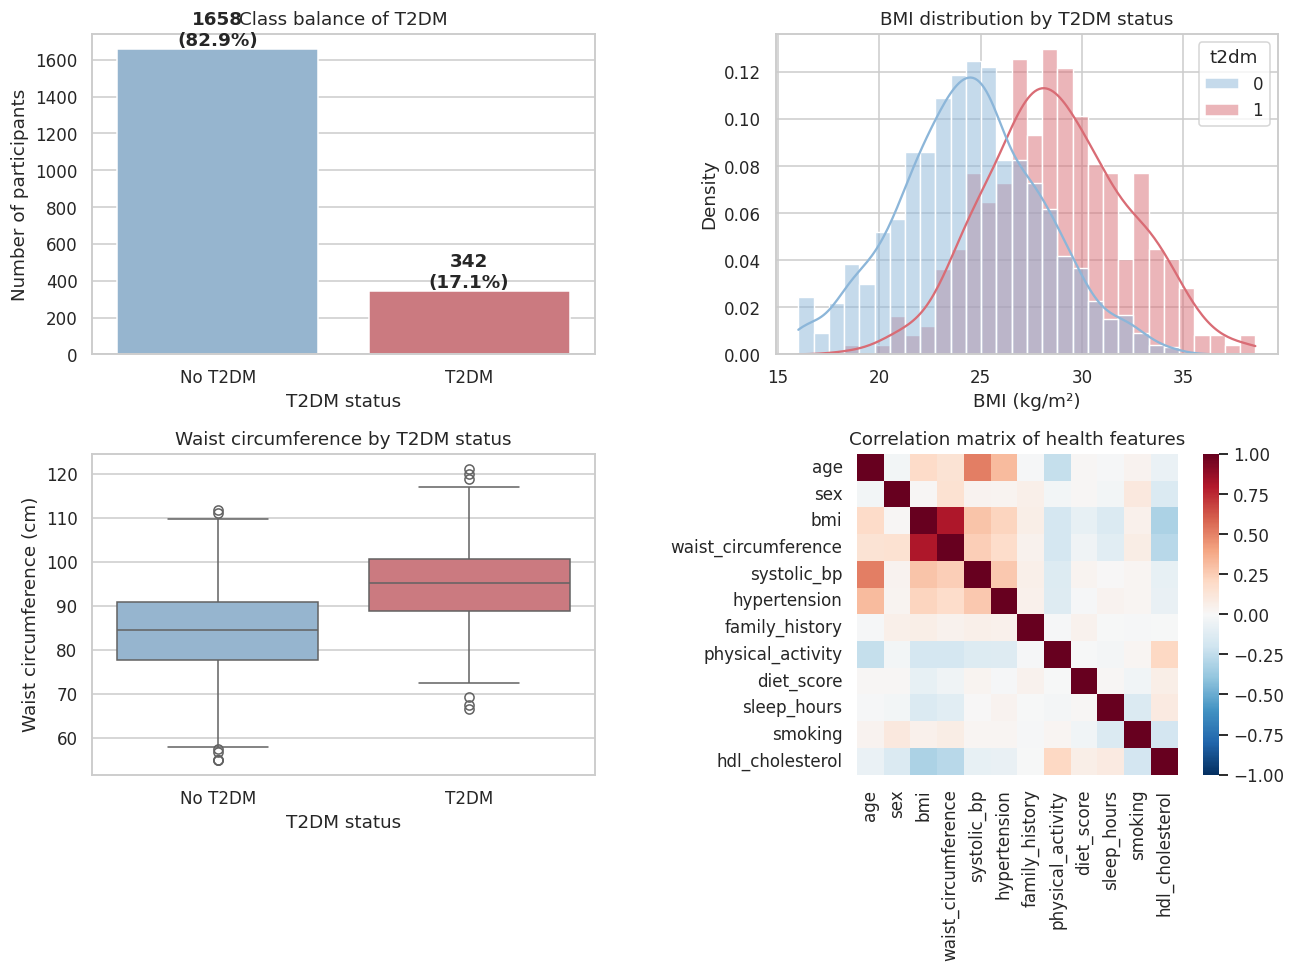

In [8]:
# 3.5 กราฟ EDA หลัก
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# (1) Class balance
sns.countplot(
    data=df,
    x="t2dm",
    hue="t2dm",
    palette=["#8CB6D9", "#D96C75"],
    legend=False,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Class balance of T2DM")
axes[0, 0].set_xlabel("T2DM status")
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(["No T2DM", "T2DM"])
axes[0, 0].set_ylabel("Number of participants")

for i, count in enumerate(class_counts):
    axes[0, 0].text(i, count + 20, f"{count}\n({count / len(df):.1%})",
                    ha="center", fontweight="bold")

# (2) BMI distribution by target
sns.histplot(
    data=df,
    x="bmi",
    hue="t2dm",
    bins=30,
    kde=True,
    stat="density",
    common_norm=False,
    palette=["#8CB6D9", "#D96C75"],
    ax=axes[0, 1]
)
axes[0, 1].set_title("BMI distribution by T2DM status")
axes[0, 1].set_xlabel("BMI (kg/m²)")

# (3) Waist circumference by target
sns.boxplot(
    data=df,
    x="t2dm",
    y="waist_circumference",
    hue="t2dm",
    palette=["#8CB6D9", "#D96C75"],
    legend=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Waist circumference by T2DM status")
axes[1, 0].set_xlabel("T2DM status")
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels(["No T2DM", "T2DM"])
axes[1, 0].set_ylabel("Waist circumference (cm)")

# (4) Correlation heatmap
corr = df[feature_cols].corr()

sns.heatmap(
    corr,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Correlation matrix of health features")

plt.tight_layout()
plt.show()

**สิ่งที่พบจากการ EDA**

1. กลุ่ม `t2dm = 1` มีประมาณ 15–20% ของข้อมูล จึงเป็นปัญหา class imbalance และไม่ควรใช้ accuracy เป็นตัวชี้วัดหลักเพียงตัวเดียว

2. `BMI` และ`รอบเอว`ของกลุ่ม T2DM มีแนวโน้มสูงกว่ากลุ่มไม่มี T2DM ตามกลไกที่กำหนดไว้

3. ตัวแปรบางคู่มีความสัมพันธ์กัน เช่น BMI กับรอบเอว และอายุกับความดันตัวบน

4. ความสัมพันธ์ระหว่าง features อาจทำให้ coefficient ของ Logistic Regression ถูกแบ่งอิทธิพลระหว่างตัวแปรที่ใกล้เคียงกัน

5. มี missing values ประมาณ 4% ในแต่ละ feature ซึ่งจะจัดการภายหลังด้วย median imputation ที่ fit จาก training set เท่านั้น

### **Part4: Data Preparation and Train/Validation/Test Split**

แบ่งข้อมูลเป็น training set, validation set และ test set ในสัดส่วน 60/20/20

- Training set ใช้ฝึกโมเดล

- Validation set ใช้เลือกโมเดลและปรับ threshold

- Test set ใช้รายงานผลสุดท้ายเพียงครั้งเดียว

In [9]:
# กำหนด features และ target
feature_cols = [col for col in df.columns if col not in ["participant_id", "t2dm"]]

X = df[feature_cols].copy()
y = df["t2dm"].copy()

print(f"จำนวน features: {X.shape[1]}")
print("Features:", list(X.columns))

จำนวน features: 12
Features: ['age', 'sex', 'bmi', 'waist_circumference', 'systolic_bp', 'hypertension', 'family_history', 'physical_activity', 'diet_score', 'sleep_hours', 'smoking', 'hdl_cholesterol']


In [10]:
# แบ่งครั้งที่ 1: แยก test set 20%
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

In [11]:
# แบ่งครั้งที่ 2: แบ่งส่วนที่เหลือเป็น train 60% และ validation 20%
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,   # 25% ของ 80% = 20% ของข้อมูลทั้งหมด
    stratify=y_temp,
    random_state=SEED
)

In [12]:
split_summary = pd.DataFrame({
    "dataset": ["Train", "Validation", "Test"],
    "n": [len(X_train), len(X_val), len(X_test)],
    "percent_of_all_data": [
        len(X_train) / len(X),
        len(X_val) / len(X),
        len(X_test) / len(X),
    ],
    "t2dm_prevalence": [
        y_train.mean(),
        y_val.mean(),
        y_test.mean(),
    ],
})

In [13]:
display(
    split_summary.assign(
        percent_of_all_data=lambda x: (x["percent_of_all_data"] * 100).round(1),
        t2dm_prevalence=lambda x: (x["t2dm_prevalence"] * 100).round(1)
    )
)

,dataset,n,percent_of_all_data,t2dm_prevalence
0,Train,1200,60.0,17.2
1,Validation,400,20.0,17.0
2,Test,400,20.0,17.0


**Preprocessing ป้องกัน Data Leakage**

ข้อมูลมี missing values ประมาณ 4% จึงใช้ median imputation เพื่อเติมค่าที่หายไป และใช้ StandardScaler เพื่อปรับสเกลตัวแปรก่อนใช้กับ Logistic Regression และ MLP

In [14]:
# สร้าง preprocessing pipeline
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# fit เฉพาะ training set
X_train_s = preprocessor.fit_transform(X_train)

# validation และ test ใช้ transform อย่างเดียว
X_val_s = preprocessor.transform(X_val)
X_test_s = preprocessor.transform(X_test)

print("Shape after preprocessing")
print("Train:", X_train_s.shape)
print("Validation:", X_val_s.shape)
print("Test:", X_test_s.shape)

print("\nMean of scaled train data:", round(X_train_s.mean(), 4))
print("Mean of scaled test data:", round(X_test_s.mean(), 4))

Shape after preprocessing
Train: (1200, 12)
Validation: (400, 12)
Test: (400, 12)

Mean of scaled train data: 0.0
Mean of scaled test data: -0.0276


In [15]:
# median ที่เรียนรู้จาก training set เท่านั้นเพื่อตรวจสอบว่าไม่มี data leakage
train_medians = pd.Series(
    preprocessor.named_steps["imputer"].statistics_,
    index=feature_cols
)

display(train_medians.to_frame("median_from_train_set").round(2))

print("Missing values after preprocessing")
print("Train:", np.isnan(X_train_s).sum())
print("Validation:", np.isnan(X_val_s).sum())
print("Test:", np.isnan(X_test_s).sum())

,median_from_train_set
age,51.91
sex,0.00
bmi,25.05
waist_circumference,86.09
systolic_bp,116.54
hypertension,1.00
family_history,0.00
physical_activity,167.36
diet_score,5.44
sleep_hours,6.95


Missing values after preprocessing
Train: 0
Validation: 0
Test: 0


**Note**

1. ข้อมูลถูกแบ่งเป็น train 1,200 คน, validation 400 คน และ test 400 คน

2. ใช้ `stratify=y` เพื่อรักษาสัดส่วน T2DM ให้ใกล้เคียงกันในทุกชุดข้อมูล

3. เติม missing values ด้วย median ที่คำนวณจาก train set เท่านั้น

4. ใช้ scaler ที่ fit จาก train set และนำไป transform validation/test

5. Validation set จะใช้เลือกโมเดลและ threshold

6. Test set จะไม่ถูกใช้ระหว่างการพัฒนาโมเดล และใช้รายงานผลสุดท้ายเพียงครั้งเดียว

### **Part 5: Baseline Model**

ก่อนฝึกโมเดลหลัก สร้าง baseline ด้วย `DummyClassifier(strategy="most_frequent")` ซึ่งจะทายคลาสที่พบมากที่สุดเสมอ ในข้อมูลนี้คือกลุ่มไม่มี T2DM หากโมเดลจริงมีผลใกล้เคียงกับ baseline แปลว่าโมเดลอาจยังไม่มีประโยชน์สำหรับการคัดกรอง

In [16]:
# สร้าง baseline model: ทายคลาสที่พบบ่อยที่สุดเสมอ
dummy_model = DummyClassifier(
    strategy="most_frequent",
    random_state=SEED
)

# ฝึกด้วย training set
dummy_model.fit(X_train_s, y_train)

# ทำนายบน test set
y_pred_dummy = dummy_model.predict(X_test_s)

# คำนวณ metrics
dummy_accuracy = accuracy_score(y_test, y_pred_dummy)
dummy_recall = recall_score(y_test, y_pred_dummy, zero_division=0)
dummy_precision = precision_score(y_test, y_pred_dummy, zero_division=0)

baseline_results = pd.DataFrame({
    "model": ["DummyClassifier (most frequent)"],
    "accuracy": [dummy_accuracy],
    "recall": [dummy_recall],
    "precision": [dummy_precision],
})

display(baseline_results.round(3))

,model,accuracy,recall,precision
0,DummyClassifier (most frequent),0.83,0.0,0.0


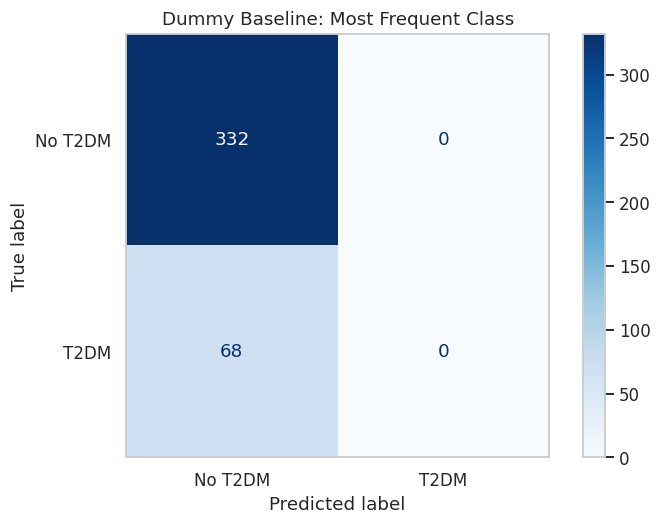

              precision    recall  f1-score   support

     No T2DM       0.83      1.00      0.91       332
        T2DM       0.00      0.00      0.00        68

    accuracy                           0.83       400
   macro avg       0.41      0.50      0.45       400
weighted avg       0.69      0.83      0.75       400



In [17]:
# Confusion matrix ของ baseline
cm_dummy = confusion_matrix(y_test, y_pred_dummy, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dummy,
    display_labels=["No T2DM", "T2DM"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Dummy Baseline: Most Frequent Class")
plt.grid(False)
plt.show()

print(
    classification_report(
        y_test,
        y_pred_dummy,
        target_names=["No T2DM", "T2DM"],
        zero_division=0
    )
)

**Note**

1. `DummyClassifier` ทายว่าทุกคน “ไม่มี T2DM” เพราะเป็นคลาสที่พบมากที่สุด

2. โมเดลอาจได้ accuracy ค่อนข้างสูง เพราะข้อมูลส่วนใหญ่ไม่มี T2DM

3. แต่ recall ของกลุ่ม T2DM จะเป็น 0 เพราะ baseline ไม่สามารถตรวจพบผู้ที่มี T2DM ได้เลย

4. ดังนั้น accuracy เพียงอย่างเดียวไม่เพียงพอสำหรับงานคัดกรองโรค

5. Logistic Regression, Random Forest และ MLP ต้องมี recall, ROC-AUC และ PR-AUC สูงกว่า baseline จึงจะแสดงประโยชน์ของโมเดล

### **Part6: Model Development and Validation Comparison**

1. Logistic Regression: ตีความ coefficient ได้ง่าย และเหมาะเป็น baseline เชิงคลินิก

2. Random Forest: เรียนรู้ความสัมพันธ์แบบไม่เป็นเส้นตรงและ interaction ระหว่างตัวแปรได้

3. MLPClassifier: neural network ขนาดเล็ก สำหรับเปรียบเทียบกับโมเดลแบบดั้งเดิม

In [18]:
# 1) Logistic Regression
logreg_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED
)

In [19]:
# 2) Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=8,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

In [20]:
# 3) Multi-Layer Perceptron
mlp_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.001,
    batch_size=64,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    random_state=SEED
)

In [21]:
models = {
    "Logistic Regression": logreg_model,
    "Random Forest": rf_model,
    "MLP": mlp_model,
}

In [22]:
# ฝึกทุกโมเดลด้วย training set เท่านั้น
for name, model in models.items():
    model.fit(X_train_s, y_train)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Random Forest
Trained: MLP


In [23]:
# ประเมินผลเบื้องต้นบน validation set
validation_probs = {}
validation_rows = []

for name, model in models.items():
    prob = model.predict_proba(X_val_s)[:, 1]
    pred_05 = (prob >= 0.50).astype(int)

    validation_probs[name] = prob

    validation_rows.append({
        "model": name,
        "validation_accuracy": accuracy_score(y_val, pred_05),
        "validation_recall_at_0.50": recall_score(y_val, pred_05),
        "validation_precision_at_0.50": precision_score(
            y_val, pred_05, zero_division=0
        ),
        "validation_roc_auc": roc_auc_score(y_val, prob),
        "validation_pr_auc": average_precision_score(y_val, prob),
    })

validation_results = (
    pd.DataFrame(validation_rows)
    .sort_values("validation_pr_auc", ascending=False)
    .reset_index(drop=True)
)

display(validation_results.round(3))

,model,validation_accuracy,validation_recall_at_0.50,validation_precision_at_0.50,validation_roc_auc,validation_pr_auc
0,Logistic Regression,0.820,0.838,0.483,0.885,0.733
1,MLP,0.885,0.426,0.806,0.883,0.691
2,Random Forest,0.850,0.735,0.543,0.892,0.689


โมเดลที่ได้ PR-AUC สูงที่สุดบน validation set: Logistic Regression


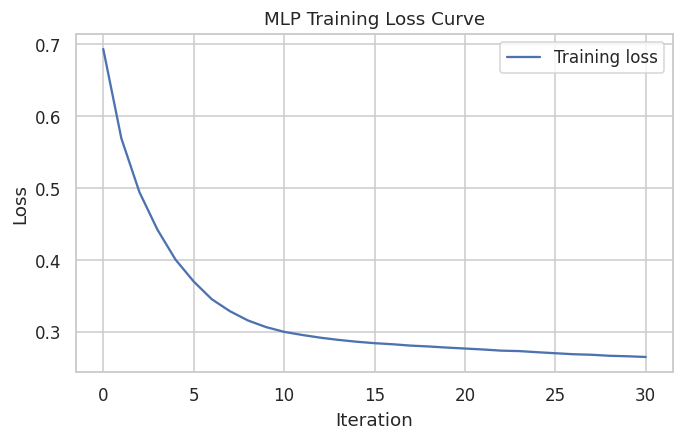

In [24]:
# เลือกโมเดลเบื้องต้นจาก PR-AUC บน validation set
best_model_name = validation_results.loc[0, "model"]
best_model = models[best_model_name]

print(f"โมเดลที่ได้ PR-AUC สูงที่สุดบน validation set: {best_model_name}")

# ดู learning curve ของ MLP เพื่อดูแนวโน้มการเรียนรู้
plt.figure(figsize=(7, 4))
plt.plot(mlp_model.loss_curve_, label="Training loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("MLP Training Loss Curve")
plt.legend()
plt.show()

**Note**

1. ทั้งสามโมเดลฝึกจาก training set เดียวกัน และใช้ validation set เดียวกันในการเปรียบเทียบ

2. ในขั้นนี้ใช้ผลจาก validation set เพื่อเลือกโมเดลและปรับ threshold เท่านั้น

3. เลือกโมเดลเบื้องต้นจาก PR-AUC เพราะข้อมูลมี class imbalance และต้องการพิจารณาความสามารถในการระบุผู้ที่มี T2DM

4. Recall ที่ threshold 0.50 เป็นเพียงจุดเริ่มต้น เพราะ threshold สำหรับงาน screening จะปรับใน Section 7 ให้ได้ recall อย่างน้อย 0.85

### **Part7: Model Evaluation and Threshold Selection**

เนื่องจากโครงงานนี้เป็นงานคัดกรอง ความผิดพลาดที่สำคัญคือ false negative หรือกรณีที่มี T2DM จริงแต่โมเดลทำนายว่าไม่มีความเสี่ยง ดังนั้นจึงเลือก threshold จาก validation set โดยตั้งเป้าหมายให้ Recall อย่างน้อย 0.85

In [25]:
def select_threshold_for_recall(y_true, probabilities, target_recall=0.85):
    """
    เลือก threshold จาก validation set
    เงื่อนไข: recall >= target_recall
    เลือก threshold ที่ให้ precision สูงที่สุด
    """
    precision, recall, thresholds = precision_recall_curve(
        y_true, probabilities
    )

    threshold_table = pd.DataFrame({
        "threshold": thresholds,
        "precision": precision[:-1],
        "recall": recall[:-1],
    })

    eligible = threshold_table[
        threshold_table["recall"] >= target_recall
    ]

    if len(eligible) == 0:
        print("ไม่พบ threshold ที่ได้ recall ตามเป้า จึงใช้ 0.50")
        return 0.50

    selected = eligible.sort_values(
        by=["precision", "threshold"],
        ascending=[False, False]
    ).iloc[0]

    return selected["threshold"]

In [26]:
# สร้าง predicted probability บน test set
test_probs = {
    name: model.predict_proba(X_test_s)[:, 1]
    for name, model in models.items()
}

In [27]:
# เลือก threshold จาก validation set และประเมินบน test set
thresholds = {}
test_rows = []

for name in models:
    threshold = select_threshold_for_recall(
        y_val,
        validation_probs[name],
        target_recall=0.85
    )

    thresholds[name] = threshold

    y_pred_test = (test_probs[name] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()

    test_rows.append({
        "model": name,
        "threshold_from_validation": threshold,
        "test_accuracy": accuracy_score(y_test, y_pred_test),
        "test_recall": recall_score(y_test, y_pred_test),
        "test_precision": precision_score(y_test, y_pred_test, zero_division=0),
        "test_roc_auc": roc_auc_score(y_test, test_probs[name]),
        "test_pr_auc": average_precision_score(y_test, test_probs[name]),
        "true_negative": tn,
        "false_positive": fp,
        "false_negative": fn,
        "true_positive": tp,
    })

test_results = (
    pd.DataFrame(test_rows)
    .sort_values("test_pr_auc", ascending=False)
    .reset_index(drop=True)
)

display(test_results.round(3))

,model,threshold_from_validation,test_accuracy,test_recall,test_precision,test_roc_auc,test_pr_auc,true_negative,false_positive,false_negative,true_positive
0,Logistic Regression,0.357,0.76,0.926,0.409,0.904,0.666,241,91,5,63
1,MLP,0.166,0.77,0.912,0.419,0.889,0.603,246,86,6,62
2,Random Forest,0.398,0.81,0.897,0.469,0.892,0.597,263,69,7,61


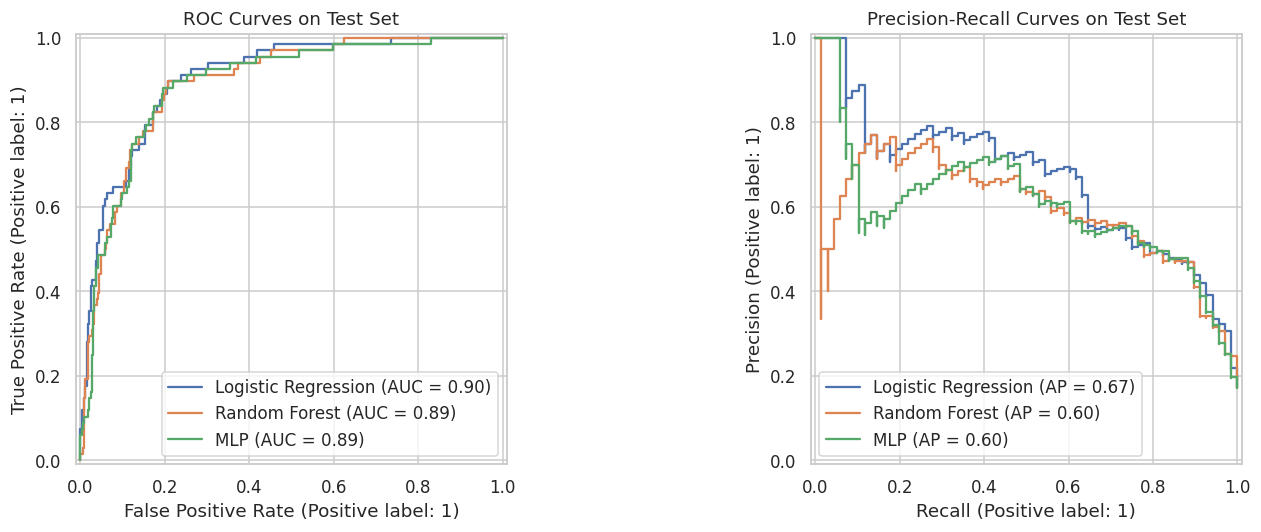

In [28]:
# ROC curve และ Precision-Recall curve บน test set
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name in models:
    RocCurveDisplay.from_predictions(
        y_test,
        test_probs[name],
        name=name,
        ax=axes[0]
    )

    PrecisionRecallDisplay.from_predictions(
        y_test,
        test_probs[name],
        name=name,
        ax=axes[1]
    )

axes[0].set_title("ROC Curves on Test Set")
axes[1].set_title("Precision-Recall Curves on Test Set")

plt.tight_layout()
plt.show()

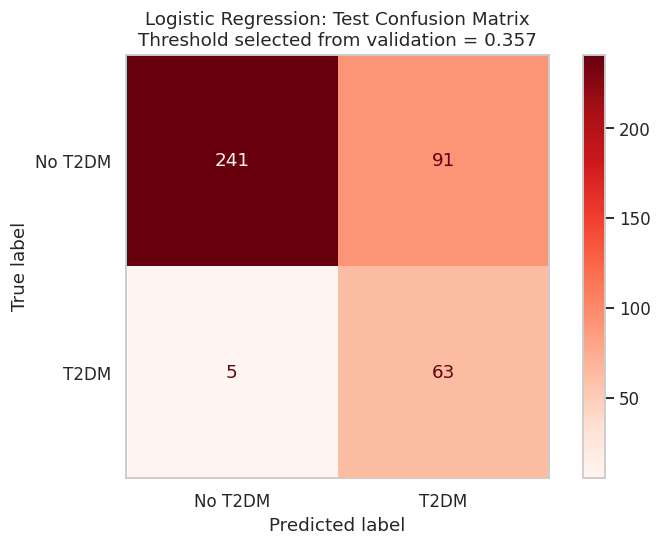

              precision    recall  f1-score   support

     No T2DM       0.98      0.73      0.83       332
        T2DM       0.41      0.93      0.57        68

    accuracy                           0.76       400
   macro avg       0.69      0.83      0.70       400
weighted avg       0.88      0.76      0.79       400



In [29]:
# รายงาน confusion matrix ของโมเดลที่เลือกจาก validation set
final_threshold = thresholds[best_model_name]
y_pred_final = (test_probs[best_model_name] >= final_threshold).astype(int)

cm_final = confusion_matrix(y_test, y_pred_final, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["No T2DM", "T2DM"]
)

disp.plot(cmap="Reds", values_format="d")
plt.title(
    f"{best_model_name}: Test Confusion Matrix\n"
    f"Threshold selected from validation = {final_threshold:.3f}"
)
plt.grid(False)
plt.show()

print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["No T2DM", "T2DM"],
        zero_division=0
    )
)

In [30]:
# เปรียบเทียบผลของ threshold 0.50 กับ threshold ที่ปรับแล้ว
prob_final = test_probs[best_model_name]

threshold_comparison = []

for threshold_name, threshold_value in {
    "Default threshold (0.50)": 0.50,
    "Validation-selected threshold": final_threshold,
}.items():

    pred = (prob_final >= threshold_value).astype(int)

    threshold_comparison.append({
        "threshold_type": threshold_name,
        "threshold": threshold_value,
        "recall": recall_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "false_negative": ((y_test == 1) & (pred == 0)).sum(),
        "false_positive": ((y_test == 0) & (pred == 1)).sum(),
    })

display(pd.DataFrame(threshold_comparison).round(3))

,threshold_type,threshold,recall,precision,false_negative,false_positive
0,Default threshold (0.50),0.500,0.838,0.487,11,60
1,Validation-selected threshold,0.357,0.926,0.409,5,91


**Note**

1. เลือก threshold จาก validation set เท่านั้น เพื่อหลีกเลี่ยงการใช้ test set ปรับโมเดล

2. เป้าหมาย Recall ≥ 0.85 สอดคล้องกับบริบทการคัดกรอง เพราะต้องการลด false negatives

3. การลด threshold มักเพิ่ม Recall แต่ทำให้ Precision ลดลง และ false positives เพิ่มขึ้น

4. ผลบน test set อาจไม่เท่ากับ validation set แม้ใช้ threshold เดิม เพราะเป็นข้อมูลคนละชุด

5. โมเดลสุดท้ายถูกเลือกจาก PR-AUC บน validation set ไม่ใช่จากผลบน test set

### **Part8: Feature Reduction, Explainability and Error Analysis**

ส่วนนี้มี 3 เป้าหมาย

1. เปรียบเทียบผลของการลดจำนวน features จาก 12 เหลือ 8 และ 5 ตัวแปร

2. ตรวจว่าโมเดลให้ความสำคัญกับตัวแปรสอดคล้องกับ TRUE_COEF ที่ใช้สร้างข้อมูลหรือไม่

3. วิเคราะห์ false negative ซึ่งเป็นความผิดพลาดสำคัญของงานคัดกรอง

**8.1 Experiment 3: Feature Reduction**

กำหนด feature sets ไว้ล่วงหน้า ดังนี้

In [31]:
feature_sets = {
    "Full 12 features": [
        "age", "sex", "bmi", "waist_circumference",
        "systolic_bp", "hypertension", "family_history",
        "physical_activity", "diet_score", "sleep_hours",
        "smoking", "hdl_cholesterol"
    ],

    "Core 8 features": [
        "age", "bmi", "waist_circumference", "systolic_bp",
        "hypertension", "family_history",
        "physical_activity", "diet_score"
    ],

    "Minimal 5 features": [
        "age", "bmi", "waist_circumference",
        "hypertension", "family_history"
    ],
}

ใช้โมเดลที่เลือกจาก validation set ใน Section 6 และสร้าง preprocessing pipeline ใหม่สำหรับแต่ละ feature set เพื่อให้ median imputation และ scaling เรียนรู้จาก training set ของ features ชุดนั้นเท่านั้น

In [32]:
from sklearn.base import clone

feature_reduction_rows = []

for set_name, selected_features in feature_sets.items():

    # สร้าง pipeline ใหม่ของแต่ละ feature set
    feature_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", clone(models[best_model_name]))
    ])

    # ฝึกด้วย training set เท่านั้น
    feature_pipeline.fit(X_train[selected_features], y_train)

    # เลือก threshold บน validation set
    val_prob = feature_pipeline.predict_proba(
        X_val[selected_features]
    )[:, 1]

    selected_threshold = select_threshold_for_recall(
        y_val,
        val_prob,
        target_recall=0.85
    )

    # ประเมินผลบน test set
    test_prob = feature_pipeline.predict_proba(
        X_test[selected_features]
    )[:, 1]

    test_pred = (test_prob >= selected_threshold).astype(int)

    feature_reduction_rows.append({
        "feature_set": set_name,
        "n_features": len(selected_features),
        "threshold": selected_threshold,
        "test_recall": recall_score(y_test, test_pred),
        "test_precision": precision_score(
            y_test, test_pred, zero_division=0
        ),
        "test_roc_auc": roc_auc_score(y_test, test_prob),
        "test_pr_auc": average_precision_score(y_test, test_prob),
        "false_negative": ((y_test == 1) & (test_pred == 0)).sum(),
    })

feature_reduction_results = pd.DataFrame(feature_reduction_rows)
display(feature_reduction_results.round(3))

,feature_set,n_features,threshold,test_recall,test_precision,test_roc_auc,test_pr_auc,false_negative
0,Full 12 features,12,0.357,0.926,0.409,0.904,0.666,5
1,Core 8 features,8,0.412,0.882,0.423,0.896,0.648,8
2,Minimal 5 features,5,0.298,0.941,0.342,0.882,0.621,4


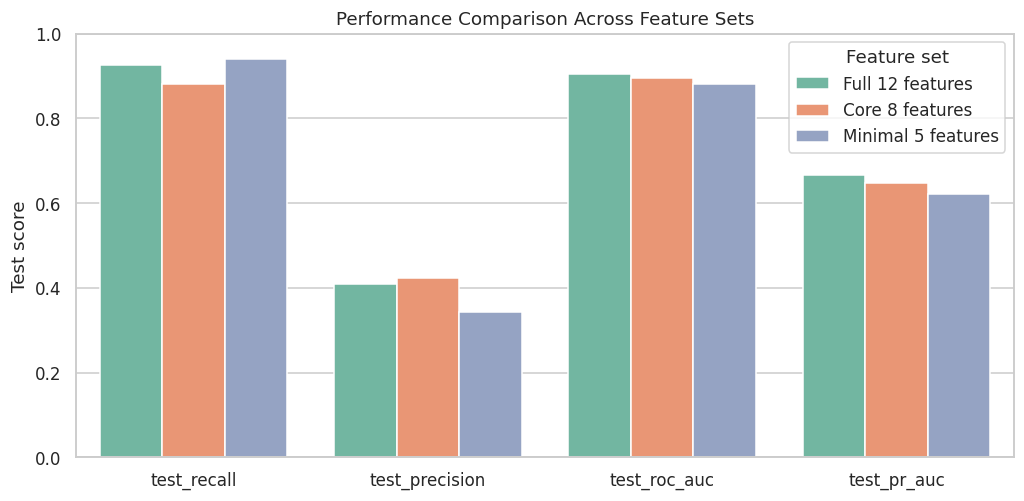

In [33]:
# กราฟเปรียบเทียบ performance ของแต่ละ feature set
plot_data = feature_reduction_results.melt(
    id_vars=["feature_set", "n_features"],
    value_vars=["test_recall", "test_precision", "test_roc_auc", "test_pr_auc"],
    var_name="metric",
    value_name="score"
)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=plot_data,
    x="metric",
    y="score",
    hue="feature_set",
    palette="Set2"
)
plt.ylim(0, 1)
plt.title("Performance Comparison Across Feature Sets")
plt.xlabel("")
plt.ylabel("Test score")
plt.legend(title="Feature set")
plt.show()

**8.2 Experiment 4: Explainability**

เปรียบเทียบ coefficient ที่ Logistic Regression เรียนรู้กับ `TRUE_COEF` ที่ใช้สร้างข้อมูล และใช้ permutation importance เพื่อดูว่าการสลับค่าตัวแปรใดทำให้ประสิทธิภาพของโมเดลลดลงมากที่สุด

In [34]:
# Logistic Regression coefficients ที่เรียนรู้จาก full 12 features
logreg_coef = pd.Series(
    logreg_model.coef_[0],
    index=feature_cols,
    name="learned_logistic_coefficient"
)

In [35]:
# TRUE_COEF ที่ใช้สร้าง synthetic data
true_coef_series = pd.Series(
    TRUE_COEF,
    name="true_coefficient"
)

In [36]:
# Permutation importance ของโมเดลที่เลือก
perm_result = permutation_importance(
    best_model,
    X_test_s,
    y_test,
    scoring="roc_auc",
    n_repeats=30,
    random_state=SEED,
    n_jobs=-1
)

perm_importance = pd.Series(
    perm_result.importances_mean,
    index=feature_cols,
    name="permutation_importance"
)

importance_comparison = pd.concat(
    [true_coef_series, logreg_coef, perm_importance],
    axis=1
)

importance_comparison["abs_true_coef"] = (
    importance_comparison["true_coefficient"].abs()
)

importance_comparison = importance_comparison.sort_values(
    "abs_true_coef",
    ascending=False
)

display(importance_comparison.round(3))

,true_coefficient,learned_logistic_coefficient,permutation_importance,abs_true_coef
bmi,0.75,0.862,0.038,0.75
family_history,0.65,0.635,0.044,0.65
hypertension,0.55,0.809,0.041,0.55
waist_circumference,0.50,0.524,0.007,0.50
age,0.45,0.796,0.037,0.45
physical_activity,-0.40,-0.310,0.009,0.40
systolic_bp,0.30,0.133,0.003,0.30
diet_score,-0.28,-0.156,0.003,0.28
hdl_cholesterol,-0.25,-0.136,0.005,0.25
smoking,0.18,0.147,0.001,0.18


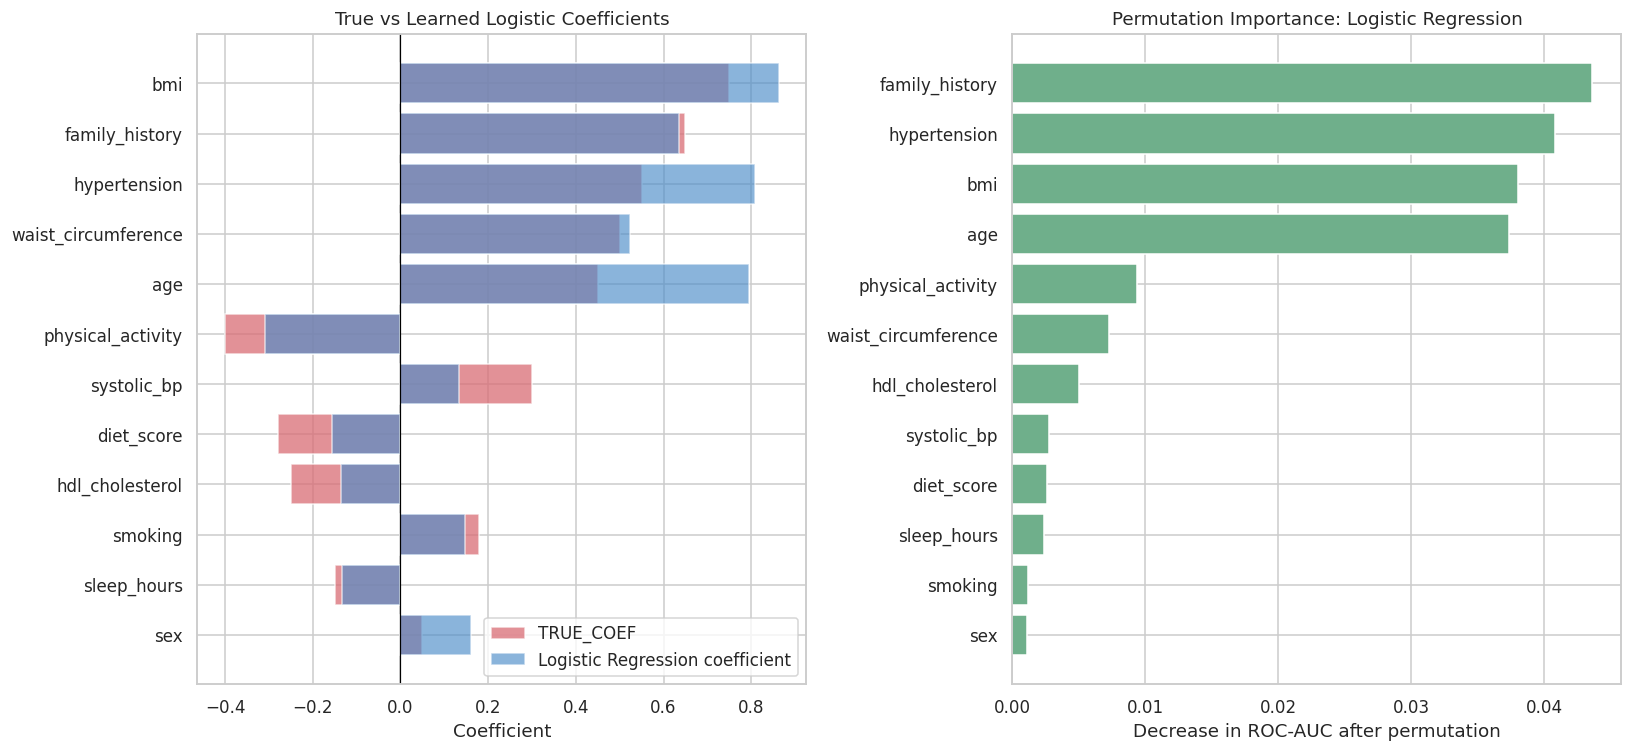

In [37]:
# กราฟเปรียบเทียบ TRUE_COEF กับ Logistic Regression coefficient
plot_coef = importance_comparison.sort_values(
    "true_coefficient",
    key=np.abs,
    ascending=True
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].barh(
    plot_coef.index,
    plot_coef["true_coefficient"],
    alpha=0.75,
    label="TRUE_COEF",
    color="#D96C75"
)

axes[0].barh(
    plot_coef.index,
    plot_coef["learned_logistic_coefficient"],
    alpha=0.65,
    label="Logistic Regression coefficient",
    color="#4C8CC9"
)

axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("True vs Learned Logistic Coefficients")
axes[0].set_xlabel("Coefficient")
axes[0].legend()

perm_plot = importance_comparison.sort_values(
    "permutation_importance",
    ascending=True
)

axes[1].barh(
    perm_plot.index,
    perm_plot["permutation_importance"],
    color="#6FAF8B"
)

axes[1].set_title(f"Permutation Importance: {best_model_name}")
axes[1].set_xlabel("Decrease in ROC-AUC after permutation")

plt.tight_layout()
plt.show()

**8.3 False-Negative Analysis**

In [38]:
# รวมข้อมูลดิบกับผลทำนายของโมเดลสุดท้าย
error_df = X_test.copy()

error_df["true_t2dm"] = y_test.values
error_df["predicted_t2dm"] = y_pred_final
error_df["predicted_probability"] = test_probs[best_model_name]

# แยกกลุ่มผลลัพธ์
false_negative_cases = error_df[
    (error_df["true_t2dm"] == 1) &
    (error_df["predicted_t2dm"] == 0)
]

true_positive_cases = error_df[
    (error_df["true_t2dm"] == 1) &
    (error_df["predicted_t2dm"] == 1)
]

print(f"จำนวน false negatives: {len(false_negative_cases)}")
print(f"จำนวน true positives: {len(true_positive_cases)}")

จำนวน false negatives: 5
จำนวน true positives: 63


In [39]:
# เปรียบเทียบค่าเฉลี่ยของกลุ่มที่โมเดลพลาดและกลุ่มที่ตรวจพบ
error_feature_summary = pd.DataFrame({
    "false_negative_mean": false_negative_cases[feature_cols].mean(),
    "true_positive_mean": true_positive_cases[feature_cols].mean(),
    "all_test_negative_mean": error_df[
        error_df["true_t2dm"] == 0
    ][feature_cols].mean(),
}).round(2)

display(error_feature_summary)

,false_negative_mean,true_positive_mean,all_test_negative_mean
age,44.27,60.63,48.98
sex,0.50,0.59,0.45
bmi,26.38,28.35,24.60
waist_circumference,88.61,93.46,84.64
systolic_bp,116.07,125.61,114.14
hypertension,0.60,1.00,0.63
family_history,0.20,0.56,0.20
physical_activity,154.69,125.68,171.44
diet_score,6.77,4.74,5.48
sleep_hours,6.47,6.78,6.94


In [40]:
# แสดง false negative ที่มี probability ใกล้ threshold มากที่สุด
fn_display_cols = [
    "age", "bmi", "waist_circumference",
    "hypertension", "family_history",
    "physical_activity", "diet_score",
    "predicted_probability"
]

display(
    false_negative_cases[fn_display_cols]
    .sort_values("predicted_probability", ascending=False)
    .head(10)
    .round(2)
)

,age,bmi,waist_circumference,hypertension,family_history,physical_activity,diet_score,predicted_probability
1914,67.47,29.79,93.03,0.0,0.0,184.05,NaN,0.32
176,72.53,23.17,81.10,1.0,0.0,178.43,9.19,0.25
1196,36.04,27.27,91.71,1.0,0.0,156.71,5.19,0.23
888,19.48,28.46,88.61,1.0,0.0,105.48,6.84,0.20
1282,25.82,23.22,NaN,0.0,1.0,148.77,5.87,0.04


**Note**

1. หาก Core 8 features ให้ผลใกล้เคียง Full 12 features อาจเหมาะกับการคัดกรองที่เก็บข้อมูลง่ายขึ้น

2. หาก Minimal 5 features มี Recall ลดลงมาก แสดงว่าข้อมูลเพิ่มเติม เช่น พฤติกรรมสุขภาพและความดัน ช่วยเพิ่มความสามารถในการคัดกรอง

3. ตัวแปรที่มี TRUE_COEF สูง เช่น BMI, ประวัติครอบครัว, ความดันสูง และรอบเอว ควรมีความสำคัญสูงในโมเดลด้วย

4. coefficient ที่โมเดลเรียนรู้อาจไม่เท่ากับ TRUE_COEF เพราะ features หลายตัวมีความสัมพันธ์กัน เช่น BMI กับรอบเอว

5. การลด threshold อาจตรวจพบ false negatives เพิ่มขึ้น แต่จะเพิ่ม false positives ด้วย

### **Part 9: Summary**

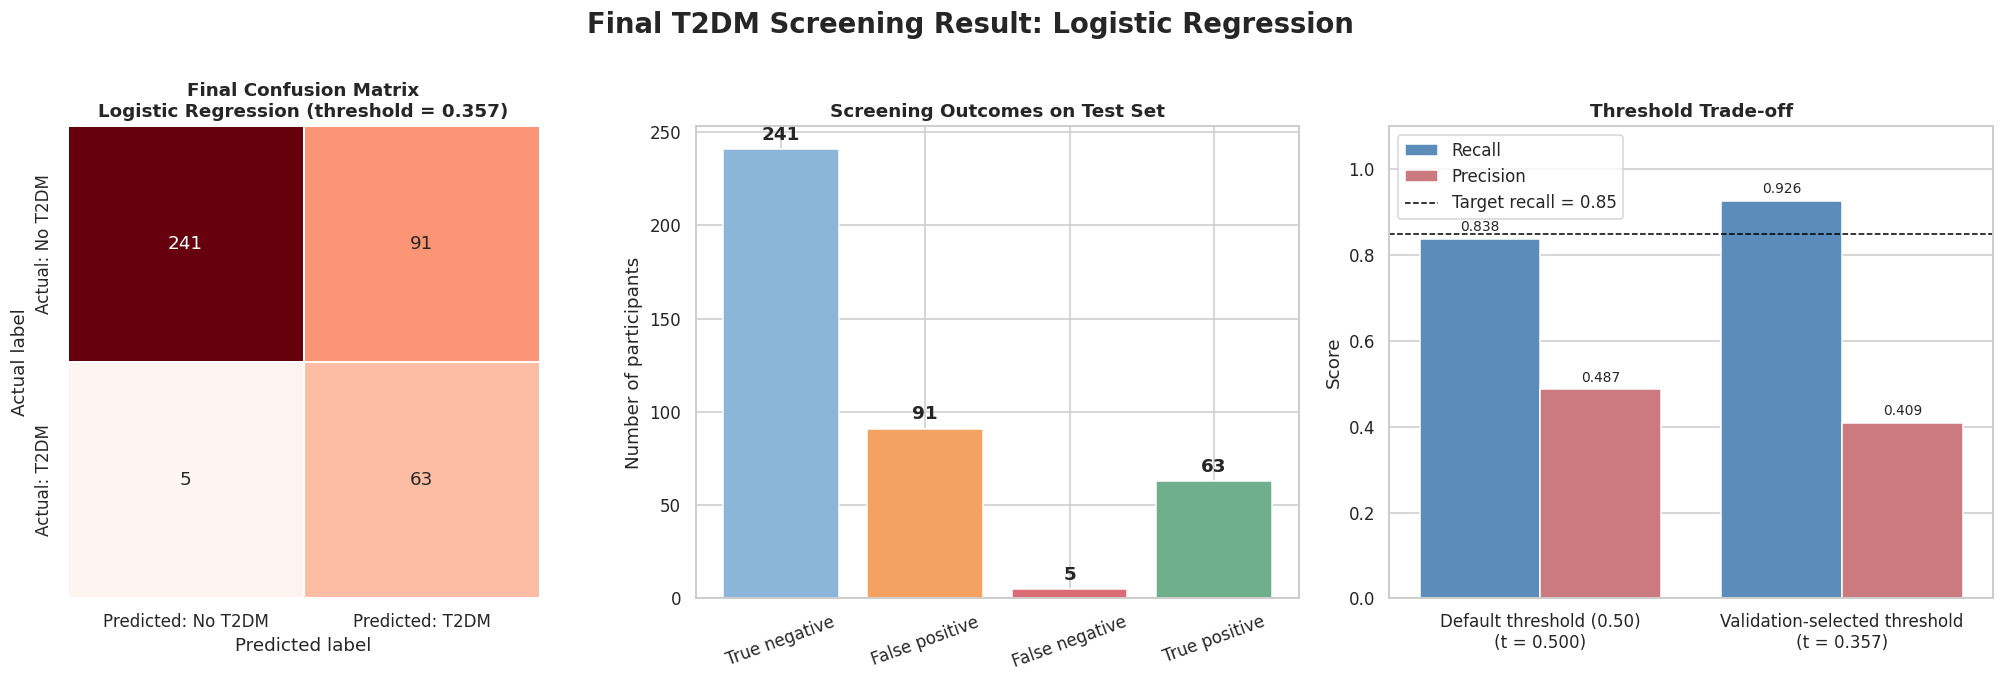

In [41]:
# ============================================================
# Final Visual Summary for Presentation / Report
# รันหลัง Section 8
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix

sns.set_theme(style="whitegrid", context="notebook")

# ---------- เตรียมค่าของโมเดลสุดท้าย ----------
cm = confusion_matrix(y_test, y_pred_final, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

final_result = test_results[
    test_results["model"] == best_model_name
].iloc[0]

final_threshold = thresholds[best_model_name]

def add_bar_labels(ax, fmt="{:.3f}"):
    for container in ax.containers:
        labels = [fmt.format(bar.get_height()) for bar in container]
        ax.bar_label(container, labels=labels, padding=3, fontsize=9)


# ============================================================
# Figure 1: Final Model Screening Result
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

# 1) Confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    cbar=False,
    square=True,
    linewidths=1,
    linecolor="white",
    xticklabels=["Predicted: No T2DM", "Predicted: T2DM"],
    yticklabels=["Actual: No T2DM", "Actual: T2DM"],
    ax=axes[0]
)

axes[0].set_title(
    f"Final Confusion Matrix\n{best_model_name} (threshold = {final_threshold:.3f})",
    fontweight="bold"
)
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("Actual label")


# 2) จำนวนผลการคัดกรอง
outcome_counts = pd.DataFrame({
    "Outcome": [
        "True negative",
        "False positive",
        "False negative",
        "True positive"
    ],
    "Count": [tn, fp, fn, tp],
    "Color": ["#8CB6D9", "#F4A261", "#D96C75", "#6FAF8B"]
})

axes[1].bar(
    outcome_counts["Outcome"],
    outcome_counts["Count"],
    color=outcome_counts["Color"]
)

axes[1].set_title("Screening Outcomes on Test Set", fontweight="bold")
axes[1].set_ylabel("Number of participants")
axes[1].tick_params(axis="x", rotation=20)

for i, value in enumerate(outcome_counts["Count"]):
    axes[1].text(i, value + 5, str(value), ha="center", fontweight="bold")


# 3) ผลของ threshold ต่อ Recall และ Precision
# แก้ไข: แปลง list ให้เป็น DataFrame ก่อนเรียกใช้เมธอด melt
threshold_plot = pd.DataFrame(threshold_comparison).melt(
    id_vars=["threshold_type", "threshold"],
    value_vars=["recall", "precision"],
    var_name="Metric",
    value_name="Score"
)

threshold_plot["Metric"] = threshold_plot["Metric"].replace({
    "recall": "Recall",
    "precision": "Precision"
})

threshold_plot["Label"] = threshold_plot.apply(
    lambda row: f"{row['threshold_type']}\n(t = {row['threshold']:.3f})",
    axis=1
)

sns.barplot(
    data=threshold_plot,
    x="Label",
    y="Score",
    hue="Metric",
    errorbar=None,
    palette=["#4C8CC9", "#D96C75"],
    ax=axes[2]
)

axes[2].axhline(
    0.85,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Target recall = 0.85"
)

axes[2].set_title("Threshold Trade-off", fontweight="bold")
axes[2].set_xlabel("")
axes[2].set_ylabel("Score")
axes[2].set_ylim(0, 1.10)
axes[2].legend()
add_bar_labels(axes[2])

plt.suptitle(
    f"Final T2DM Screening Result: {best_model_name}",
    fontsize=18,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.show()

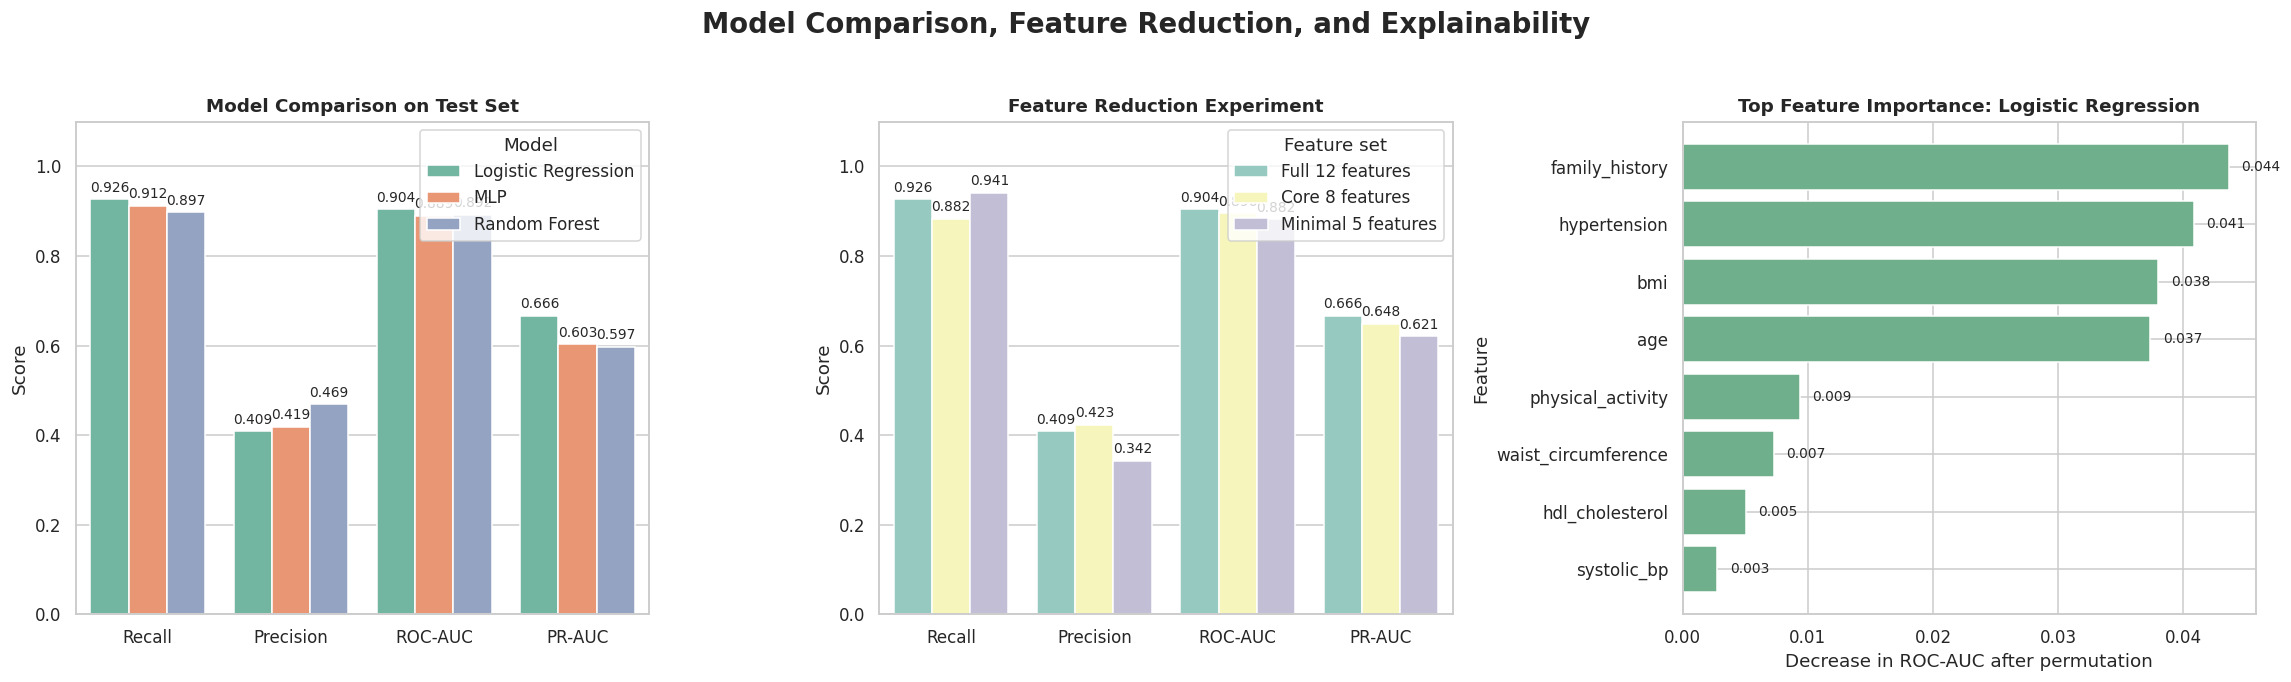

In [42]:
# ============================================================
# Figure 2: Model, Feature Set, and Explainability Comparison
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# 1) เปรียบเทียบโมเดล
model_plot = test_results.melt(
    id_vars="model",
    value_vars=[
        "test_recall",
        "test_precision",
        "test_roc_auc",
        "test_pr_auc"
    ],
    var_name="Metric",
    value_name="Score"
)

model_plot["Metric"] = model_plot["Metric"].replace({
    "test_recall": "Recall",
    "test_precision": "Precision",
    "test_roc_auc": "ROC-AUC",
    "test_pr_auc": "PR-AUC"
})

sns.barplot(
    data=model_plot,
    x="Metric",
    y="Score",
    hue="model",
    errorbar=None,
    palette="Set2",
    ax=axes[0]
)

axes[0].set_title("Model Comparison on Test Set", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.10)
axes[0].legend(title="Model")
add_bar_labels(axes[0])


# 2) เปรียบเทียบ feature sets
feature_plot = feature_reduction_results.melt(
    id_vars=["feature_set", "n_features"],
    value_vars=[
        "test_recall",
        "test_precision",
        "test_roc_auc",
        "test_pr_auc"
    ],
    var_name="Metric",
    value_name="Score"
)

feature_plot["Metric"] = feature_plot["Metric"].replace({
    "test_recall": "Recall",
    "test_precision": "Precision",
    "test_roc_auc": "ROC-AUC",
    "test_pr_auc": "PR-AUC"
})

sns.barplot(
    data=feature_plot,
    x="Metric",
    y="Score",
    hue="feature_set",
    errorbar=None,
    palette="Set3",
    ax=axes[1]
)

axes[1].set_title("Feature Reduction Experiment", fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1.10)
axes[1].legend(title="Feature set")
add_bar_labels(axes[1])


# 3) Permutation importance
importance_plot = (
    importance_comparison
    .sort_values("permutation_importance", ascending=True)
    .tail(8)
)

axes[2].barh(
    importance_plot.index,
    importance_plot["permutation_importance"],
    color="#6FAF8B"
)

axes[2].set_title(
    f"Top Feature Importance: {best_model_name}",
    fontweight="bold"
)
axes[2].set_xlabel("Decrease in ROC-AUC after permutation")
axes[2].set_ylabel("Feature")

for i, value in enumerate(importance_plot["permutation_importance"]):
    axes[2].text(
        value + 0.001,
        i,
        f"{value:.3f}",
        va="center",
        fontsize=9
    )

plt.suptitle(
    "Model Comparison, Feature Reduction, and Explainability",
    fontsize=18,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.show()

### **Part 10: Limitations and Potential Use**

**ข้อจำกัด**

1. ข้อมูลทั้งหมดเป็นข้อมูลจำลอง ผู้จัดทำเป็นผู้กำหนดความสัมพันธ์ระหว่าง features และ T2DM เอง ผลการทดลองจึงแสดงได้เพียงว่า pipeline และโมเดลสามารถเรียนรู้จากกลไกที่กำหนดไว้ได้

2. ค่าสัมประสิทธิ์ใน TRUE_COEF ไม่ใช่ค่าความเสี่ยงจริงของผู้ป่วย และไม่ควรตีความว่าเป็นผลเชิงสาเหตุหรือใช้แทนหลักฐานทางคลินิก

3. ข้อมูล train, validation และ test ถูกสร้างจากกลไกเดียวกัน จึงยังไม่ได้ทดสอบความสามารถของโมเดลกับประชากร โรงพยาบาล หรือช่วงเวลาที่แตกต่างกัน

4. ใช้ข้อมูลที่ไม่ต้องตรวจเลือด จึงออกแบบมาเพื่อประเมินความเสี่ยงเบื้องต้นเท่านั้น ไม่สามารถใช้วินิจฉัย T2DM ได้ การวินิจฉัยต้องอาศัยการตรวจตามเกณฑ์มาตรฐาน เช่น glucose หรือ HbA1c

5. การกำหนด threshold เพื่อให้ Recall สูง อาจเพิ่ม false positives ทำให้บางคนได้รับคำแนะนำให้ตรวจยืนยันเพิ่มเติมแม้สุดท้ายจะไม่พบ T2DM



**แนวทางการนำไปใช้**

1. โมเดลควรใช้เป็นเครื่องมือคัดกรองเบื้องต้นร่วมกับแบบสอบถามสุขภาพหรือการตรวจสุขภาพในชุมชน ผู้ที่มีผลประเมินความเสี่ยงสูงควรได้รับคำแนะนำให้เข้ารับการตรวจยืนยันด้วยบุคลากรทางการแพทย์

2. โมเดลไม่ควรใช้แทนการวินิจฉัย การรักษา หรือการตัดสินใจของแพทย์ และควรแสดงข้อความอธิบายผลการประเมินให้ผู้ใช้เข้าใจว่าเป็นเพียงการคัดกรองความเสี่ยง

**สิ่งที่ต้องทำก่อนใช้กับข้อมูลจริง**

1. เก็บข้อมูลผู้ป่วยจริงภายใต้การอนุมัติด้านจริยธรรมและการคุ้มครองข้อมูลส่วนบุคคล

2. กำหนด outcome T2DM จากเกณฑ์การวินิจฉัยมาตรฐาน

3. ทดสอบโมเดลกับข้อมูลจากสถานพยาบาลหรือประชากรภายนอกชุดที่ใช้ฝึก

4. ประเมินความเป็นธรรมของโมเดลในกลุ่มอายุ เพศ หรือกลุ่มประชากรที่แตกต่างกัน

5. ประเมินผลกระทบของ false positives และ false negatives ร่วมกับบุคลากรทางการแพทย์ก่อนกำหนด threshold สำหรับใช้งานจริง

### **Part 11: References and AI Disclosure**

**References**

*1. American Diabetes Association Professional Practice Committee. Diagnosis and Classification of Diabetes: Standards of Care in Diabetes—2024. Diabetes Care. 2024;47(Supplement 1)–S42. https://doi.org/10.2337/dc24-S002*

*2. World Health Organization. Diabetes. Fact sheet. 14 November 2024. https://www.who.int/news-room/fact-sheets/detail/diabetes*

*3. Pedregosa F, Varoquaux G, Gramfort A, et al. Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research. 2011;12:2825–2830.*

*4. Breiman L. Random Forests. Machine Learning. 2001;45:5–32. https://doi.org/10.1023/A:1010933404324*

*5. Scikit-learn developers. Scikit-learn documentation. https://scikit-learn.org/stable/*

**Software and Tools**

1. Python

2. NumPy

3. pandas

4. matplotlib

5. seaborn

6. scikit-learn

**AI Disclosure**

1. ผู้จัดทำใช้ AI เป็นเครื่องมือช่วยวางโครงสร้าง Notebook ช่วยอธิบายแนวคิด machine learning ช่วยตรวจสอบความถูกต้องเบื้องต้นของโค้ด และช่วยปรับภาษาในการเขียนรายงาน

2. ผู้จัดทำเป็นผู้ตรวจสอบ ปรับแก้ และตัดสินใจเกี่ยวกับกลไกการสร้างข้อมูลจำลอง การกำหนด features การเลือกโมเดล การออกแบบการทดลอง การตั้ง threshold และการตีความผลด้วยตนเอง

3. ข้อมูลที่ใช้ในโครงงานเป็นข้อมูลจำลองทั้งหมด ผลการทดลองจึงใช้เพื่อสาธิตแนวทางการพัฒนาและประเมินโมเดลเท่านั้น ไม่ใช่หลักฐานทางคลินิก และไม่ควรนำไปใช้วินิจฉัยผู้ป่วยจริง